# Homework 3: Data analysis with Pandas and numerically solving ODEs

<img src="https://cmse.msu.edu/_assets/images/about/image001.png"
     alt="CMSE Logo"
     align="right" 
     width="200"/>

### <p style="text-align: right;"> &#9989; Put your name here </p>

## **Learning Goals**

### Content Goals
* Using pandas to work with data and clean it
* Make meaningful visual representations of the data
* Solving ODEs numerically using `solve_ivp`

### Practice Goals
- Read Python module documentation to learn how to accomplish new things that may be unfamiliar to you
___


## **Assignment instructions**

Work through the following assignment, making sure to follow all the directions and answer all the questions.

**This assignment is due at 11:59 pm on Friday, October 23.** It should be uploaded into the "Homework Assignments" submission folder for Homework #3.  Submission instructions can be found at the end of the notebook.


---
<a id="toc"></a>

## **Table of Contents and Grading**

[0. Importing the modules you will need for this assignment](#part_0)

[1. Reading, describing, and cleaning data](#part_1)  (28 points)

[2. Exploratory Data Analysis](#part_2)  (22 points)

[3. Solving ODEs with `solve_ivp`](#part_3) (28 points)

Total points possible: **78**
    

---
<a id="part_0"></a>

## **0. Importing the modules you will need for this assignment**

[Back to Top](#toc)

In this assignment you will be using `matplotlib`, `numpy`, `pandas`, and `solve_ivp`. Of course, in order to make sure you can use these modules when you need them, you have to **import** them.

Put the `import` commands you need to include to be able to use all of the above modules in this notebook in the cell below. Make sure to execute the cell before you move on!

In [ ]:
# Put your import commands here


In [1]:
### ANSWER ###
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# This isn't for credit, but just to get them in the habit of putting imports at the top of the file

---
<a id="part_1"></a>

## **1. Reading, describing, and cleaning data (28 points)**

[Back to Top](#toc)

#### &#9989;&nbsp; **Task**
With this assignment, you will find two .zip files and one CSV file. The `zipped_data_files_part1.zip` folder and `Example002.csv` contain the files you will need for part 1. If you have not yet had to "unzip" data files before, you will need to use your resources (e.g., office hours, Google, HiTA, etc.) to find out how! 

Suppose you are interested in modeling the weather of the Great Lakes.  You find some great data in the [Great Lakes Weather Data and Marine Observations](https://apps.glerl.noaa.gov/marobs/)$^{1}$ webpage that has been compiled by the [Great Lakes Environmental Research Laboratory](https://www.glerl.noaa.gov/about/), a lab that operates under NOAA. Let's check it out!


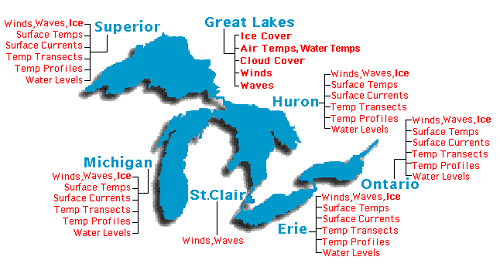Image credit: [NOAA GLERL](https://www.glerl.noaa.gov/res/Programs/ipemf/GLCFS_nextgen.html)


The data contains realtime marine data from Great Lakes buoys, coastal met stations, airports, and ships. Marine observations include wind speed, wind gust, wind direction, air temperature, dew point, cloud cover, sea level pressure, water temperature, wave height, wave period, and live tracking of Great Lakes ship locations.

Variables are descibed as follows:

| Variable name   |    stands for            |    description /unit of measurement         |  
|:---------------:|:------------------------:|--------------------------------| 
| id              | Observation Identifier   | includes 'year', 'day', 'hour', 'minute', 'station type', 'station id' and 'lake'|
| data_format     | data format              | 9 = Lake Meteorological Data (LMD) Format| 
| air_temp        | Air temperature          | degrees Centigrade             | 
| dew_point          | Dew point                | degrees Centigrade             | 
| wind_direction        | Wind direction           | degrees from, 0=north, 90=east | 
| wind_speed        | Wind speed               | meters/second                  |
| max_gust        | Maximum wind gust        | meters/second                  | 
| cloud       | Cloud cover              | percent                        | 
| solar       | Solar Radiation          | watts/meter                    | 
| pressure        | Barometric pressure      | millibars                      |
| water_temp      | Water temperature        | degrees Centigrade             | 
| wave_height         | Significant Wave height  | meters                         | 
| wave_period        | Wave period              |   seconds                             | 
|ship_lat |      North Latitude (ship observation)                 | Decimal degrees                   |                       |
|ship_long  |  West Longitude (ship observation)                  |    Decimal degrees                 |                       |


**(OPTIONAL:)** If you are interested, you may refer to the appendix for information on how this data was scraped from the web. 


$^{1}$NOAA/GLERL. Realtime Great Lakes Weather Data and Marine Observations. https://apps.glerl.noaa.gov/marobs/, accessed March 3rd, 2025.


## Part 1.1 - Looking over the data (2 points)
As you might recall from Day 12, data sometimes comes in formats that you might not be familiar with.  Figuring out how to load in the data in a useful way is one of the most common issues that you will face.

#### &#9989;&nbsp; **Task**
Run the cell below to try reading in the data from the `g202502600.lmd` file using `read_csv`.  

In [3]:
# Run this cell!
problem_data = pd.read_csv('g202502600.lmd')
problem_data.head()

,202502600001AGCM4 29 999.9 999.9 999 99.9 99.9 999 9999.9 1015.4 0.1 99.9 99.9
0,202502600001ALXN6 59 999.9 999.9 999 99.9 99...
1,202502600001APNM4 29 -1.2 999.9 260 6.2 7...
2,202502600001BHRI3 19 2.5 999.9 270 5.7 7...
3,202502600001BIGM4 09 -2.4 999.9 330 3.6 7...
4,202502600001BSBM4 19 1.0 999.9 270 16.5 21...


You probably saw that data did not load correctly.  Open the data and take a look at the file.  You might also want to look at the format sheet that is provided on the website: https://apps.glerl.noaa.gov/marobs/docs/data.lmd.fmt. 

#### &#9989;&nbsp; **Task**
**Name at least two things about how the data is formatted that might make it hard for `read_csv` to read in the data.**(2 points)

<font size=8 color="#009600">&#9998;</font> Put your answer here:  

## Part 1.2 Loading Data (5 points)

It appears we might need to use a different tool to read in the data.    

#### &#9989;&nbsp; **Task (5 points)**
1. Look at the format sheet that is provided with the dataset on the website: https://apps.glerl.noaa.gov/marobs/docs/data.lmd.fmt. Observe the format of each variable.

2. Take a look at the tools pandas has available, and read some of the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/io.html.  Is there one that looks like it might be useful in this case?
   
3. Test out the pandas tool you selected and print the first few rows to make sure it works. Make sure to separate the identifier variable into its different components, and that the columns have appropriate descriptive names!  You should end up with 21 columns in your data frame.
   
*If all goes well, you should get something that looks like this:*

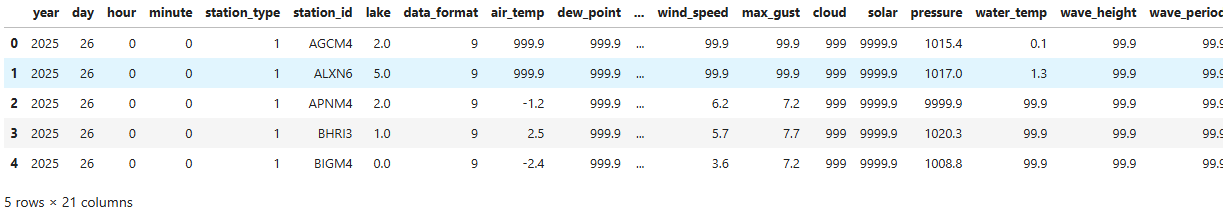

In [46]:
## your code here

## Part 1.3 Loading multiple files (4 points)

Each file only includes data from a single day, which might not be very useful.  It would be much more useful to load data from multiple days.  This is a very common thing to do in data science.  Fortunately, we can accomplish this in Python!

You have been provided with 30 data files, corresponding to daily marine data observations from day 26 to day 57 of the year 2025.

#### &#9989;&nbsp; **Task:** 
Write a `for` loop to load the data from each of the files and save all of the data into one dataframe.  Display the final dataframe. (4 points)

**Note:** Some example starter code is provided to you in the cell below to get you started, but **you will need to modify it**. In this example, the code reads in a `"Example002.csv"` file from a series of datasets that have file names of the form `"Example001.csv"`, `"Example002.csv"`, `"Example003.csv"`, and so on. You will augment this code to include a loop, and in each iteration of the loop, you will change the name of the file to be loaded using the file name format of the data files provided. 

In [4]:
# create an empty dataframe
# this is where all the data will eventually be stored
store_data = pd.DataFrame() 

# create a filename
filenumber = "{:03d}".format(2)
filename = "Example" + filenumber + ".csv"
print(filename)

# load in data to a temporary variable
temp_data = pd.read_csv(filename)

# add data to the storage variable 
store_data = pd.concat([store_data, temp_data])
store_data

Example002.csv


,A,B,C,D
0,10,8,3,6
1,4,5,3,8
2,12,15,6,2


### Some data wrangling
Before you proceed, uncomment the cell below and modify the dataframe name `df` as appropriate . Then run the cell, to see the data types in your data frame. Compare this with the data you have displayed above.

In [7]:
#store_data.dtypes

year                int64
day                 int64
hour                int64
minute              int64
station_type        int64
station_id            str
lake              float64
data_format         int64
air_temp          float64
dew_point          object
wind_direction     object
wind_speed        float64
max_gust          float64
cloud               int64
solar             float64
pressure          float64
water_temp        float64
wave_height       float64
wave_period       float64
ship_lat          float64
ship_long         float64
dtype: object

You may notice that some columns in your data frame that contain numerical measurements are neither floats nor integers. This is because there are some values that were not saved correctly as numbers, and pandas had to load the column as strings. This can present problems with data analysis later on.  

#### &#9989;&nbsp; **Task:** 
Uncomment the cell below and modify the DataFrame name as appropriate to check for strings and cast them as floats:

In [22]:
# for col in store_data.columns: #for col in df.columns:
#     if col != 'station_id':
#         print(col)
#         store_data[col] = pd.to_numeric(store_data[col],errors='coerce')

# ## Check that data types have been modified correctly:
# store_data.dtypes # df.dtypes

## Part 1.4: Slicing and performing basic statistics on data (3 points)

Now you have loaded 30 days worth of data.

#### 1.4a Slicing data for a weather prediction model (2 points)

You are going to make a lake weather model, and you have determined to use the following five measurement columns (variables) in your model: `air_temp`, `wind_speed`, `max_gust`, `dew_point`, and `water_temp`.

#### &#9989;&nbsp; **Task** 
Using the `iloc` function, create a new data frame that has only the first seven columns and the five measurement variables for your model. Display the first few rows of the new data frame. 

In [61]:
#your code here

#### 1.4b Descriptive statistics (1 point)
Now it is a good time to look at the data and see what you have. 

#### &#9989;&nbsp; **Task**
Use the `.describe()` method on your dataset to get some statistics.

In [64]:
#your code here:

## Part 1.5: Data cleaning (9 points)

Take a look at the results from the describe function.  In particular, take a look at some of mean and max values, especially for air temperature.  Do those make sense to you?

#### 1.5a &#9989;&nbsp; **Task**: 
You may have noticed there are a lot of places in the data that are filled with the digit 9.  **According to the [format guide](https://apps.glerl.noaa.gov/marobs/docs/data.lmd.fmt), what does this mean?** (1 point)

<font size=8 color="#009600">&#9998;</font> Put your answer here:  

#### 1.5b &#9989;&nbsp; **Task**: 
Use the [`replace()` method](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.replace.html) in pandas to change all such entries to `np.nan` (NaN stands for Not a Number, and this is how pandas designates a missing value). (2 points)

In [70]:
#your code here
store

####  1.5c
Now use the `.describe()` method again on your new data frame: (1 point)

In [42]:
#your code here:

#### &#9989;&nbsp; **Task**: 
Does this make the values returned by `.describe()` make more sense to you? (1 point)

<font size=8 color="#009600">&#9998;</font> Put your answer here:  

#### 1.5d Now, create a new data frame that does not have the `"NaN"` values.

#### &#9989;&nbsp; **Task:** 
Remove the missing values using the built-in pandas [`dropna()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.dropna.html) function. (1 point) 

In [48]:
#your code here

#### 1.5e Now, examine the difference in sizes between the original and clean datasets.
#### &#9989;&nbsp; **Task:** (2 points)
Determine the number of rows in each dataset from #1.5b and #1.5d (1 point). Print out your results (1 point).

In [51]:
#Your code here

#### 1.5f Let's reflect on the cleaning process.
#### &#9989;&nbsp; **Task:**
For this specific dataset and the variables you selected, would it matter if you hadn't dropped the `"NaN"` data? (1 point).

<font size=8 color="#009600">&#9998;</font> Put your answer here


## Part 1.6 - Filter the data using masking (5 points)

Now you have a clean dataset for your weather model; let us zoom in on Lake Michigan for our analysis. Suppose you want to see if the weather on the west side of Lake Michigan is correlated with the weather on the east side of Lake Michigan.  

Consider the three stations around Lake Michigan in Holland, Mackinaw, and Menominee, with sttaion IDs `'HLNM4'`, `'MACM4'`, and `'MNMM4'`, respectively. The first two are on the east side, and the third is on the west side of Lake Michigan.  (Use the [map](https://apps.glerl.noaa.gov/marobs/php/data.php?sta=9&labels=n&param=5&units=e&zoom=m) to view by station ID to see where each station is located.)


#### 1.6a &#9989;&nbsp; **Task**: Use masking to isolate data for each of these three stations. (3 points)

In [59]:
#1.6b
#your code here:

#### 1.6c &#9989;&nbsp; **Task**: 
The Menominee and Holland stations are on opposite sides of Lake Michigan. Use the `iloc` function to display the first 5 air temperature records in the Menominee and Holland datasets you have just created. (1 point.)

In [12]:
## your code here

#### 1.6d &#9989;&nbsp; **Task (1 point)**
From the results displayed, are the air temperatures similar? Provide a possible explanation for what you observe.

<font size=8 color="#009600">&#9998;</font> Put your answer here

---
<a id="part_2"></a>

## **2. Exploratory Data Analysis (22 points)**

[Back to Top](#toc)

The first step in every data science project, after obtaining the dataset, is sometimes referred to as Exploratory Data Analysis (EDA). As the name suggests, it involves exploring your dataset to identify general trends and possible correlations. Basically, you want to make sure you've got a basic sense of the properties of the data you are working with!

In this part of the assignment, you will visualize our data and look for correlations in our lake weather dataset. The focus is to explore the dataset and see what information you can pull out of it, even if you don't have a deep grasp of the discipline it comes from. In the tasks below, you will be asked to explore the data and answer some questions about it. 


#### Note:
<a id="clean_data"></a> If you were not able to get part 1 done correctly, download the `zipped_data_files_part2` zip file and extract the four CSV files in it to your working directory. Then run the cell below to load the clean dataset and use it for the rest of the assignment. You can also use this data set to check your work in part 1. 

In [ ]:
#entire (clean) dataset
clean_lake_data=pd.read_csv("clean_lake_data.csv")

#Menominee data
data_MNM=pd.read.csv("data_MNM.csv")

#Mackinaw data
data_MAC=pd.read.csv("data_MAC.csv")

#Holland data
data_HOL=pd.read.csv("data_HOL.csv")

### Part 2.1: Correlations (5 points)

In our dataset, there are columns with numerical values and those with string values. We can only look for correlations between columns with numerical (float type) values.

&#9989;&nbsp; **Task:** Using the Menominee, MI data subset you extracted in part $1.6\:b$, print or display a correlation matrix using only the five measurement variables you used in part 1. **(1 point)**

_Hint1:_ Look up the pandas `corr` function for dataframes. 

_Hint2:_ To select multiple columns, use the following notation: `df[["col1"], ["col2"]]`

In [34]:
# Put your code here

&#9989;&nbsp; **Task(4 points):** 
1. Looking at the table, would you consider any of the correlations ***between*** the columns to be _weak_? (1 pt)
2. Identify 2 pairs of variables that are _most strongly_ correlated. (1 pt)

3. For these 2 pairs of variables, describe the direction of the correlation in plain words (2 sentences, one describing each pair) (2 pts, 1 for each sentence).

<font size=8 color="#009600">&#9998;</font> Put your answer here

**1 (1pt):**  

**2 (1pts):**  

**3 (2pts):** 

### Part 2.2: Visual representation of correlations (13 points)

The numbers above gives us a quantitative measure of the correlations in the dataset. Visualization in data science is a very important skill!!! 

You have just observed some pairs of variables that are strongly correlated. In the next exercise, you will visualize the relationships between these pairs of variables as scatterplots. You will create a plot for each relationship: 1) `Variable 1` vs. `Variable 2` and 2) `Variable 3` vs. `Variable 4`.

We want to make a plot similar to the one below:

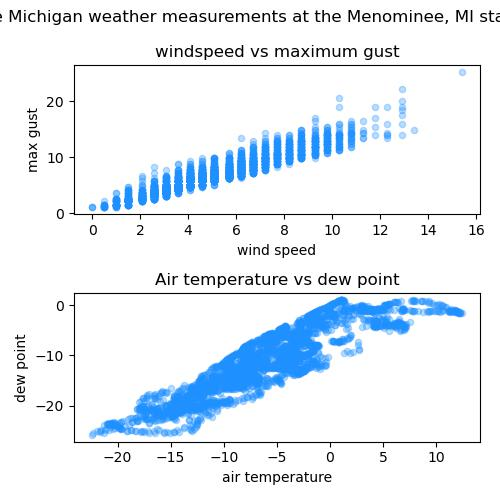

&#9989;&nbsp; **Do this (10 points):**  Use `matplotlib` to make two _scatter plots_ like the ones above **but do not recreate them (i.e. do something new!)**. For full points, do the following:

- Create 2 subplots using `plt.subplot`. Use 2 rows and 1 column **(2 points)**.
- Use `plt.figure` and the argument `figsize` to make a plot 4 inches wide x 6 inches long **(1 point)**.
- Plot  1) `Variable 1` vs. `Variable 2`and 2) `Variable 3` vs. `Variable 4`. Provide a title for each subplot **(1 point)**.
- Give the overall plot an appropriate title **(1 point)**
- Provide x-axis labels **(1 point)**.
- Provide y-axis labels **(1 point)**.
- Create variables for point size, color, and alpha outside of the code for your plots. Use the variables you created to control size, color, and alpha in your subplots. Use the same parameters for all the plots. Choose appropriate point size, color, and alpha so that you can see the relationships in your data (avoid overplotting) **(2 points, one for each)**.
- Use `tight_layout` to give your plot optimal sizing **(1 points)**.

In [37]:
# Put your code here

In [39]:
### ANSWER ###

# -- The points are given in the text above. 
# -- Partial credit if only one of the plot has the correct characteristics.

&#9989;&nbsp; **Answer the following (3 points):** Looking at the plots, 

1. Which plots looks like it has the strongest correlation? Justify your answer (1 point).
2. Which plot looks the most linear? (1 point).
3. Which of the two plots has the steepest slope? Justify your answer and look carefully at the range of values the data span. Do your best to estimate this from the plots. If you want, you can try to confirm your hunch by using the actual data values to calculate this. (2 points)

<font size=8 color="#009600">&#9998;</font> Put your answer here

**Part 1 (1pt):**  

**Part 2 (1pt):**  

**Part 3 (2pts):**  


---
<a id="part_3"></a>

## **3. Solving ODEs with `solve_ivp` (28 total points)**

[Back to Top](#toc)

&#9989;&nbsp; **3.1 (10 points)**: As you might have heard at some point, it was discovered that various water sources in Michigan have been contaminated with high levels of PFAS chemicals ([https://www.mlive.com/news/index.ssf/page/michigans_water_crisis_pfas.html](https://www.mlive.com/news/index.ssf/page/michigans_water_crisis_pfas.html)). In fact, there was [symposium](https://www.canr.msu.edu/pfas-research/Annual-Symposium/) taking place in Lansing about this very issue while I was crafting this homework assignment. Many of these chemicals are introduced by manufacturing companies improperly disposing of the by-products of the manufacturing process. 

If you consider the network of water sources in the state of Michigan (i.e. ponds, lakes, rivers, ground water), you might begin to understand how the introduction of a chemical into one location could lead an eventual contamination of the entire system -- eventually even our wonderful Lake Michigan could be impacted!

Let's take this scenario as our context for thinking about how one could build a compartmental model to study the movement of a pollutant a local pond system where a industrial factory might be dumping PFAS chemicals. Let's say that we have three ponds, $A$, $B$, and $C$, connected via streams in the following way, with the factory dumping pollutants at a rate of, $p$, into Pond $A$:

<img src="https://i.imgur.com/1dYrpNm.png" width=300px>

we can then define a set of ordinary differential equations that describe how the pollutant moves through the system that might look something like this:

$$ \frac{dA}{dt} = p - qA + sC $$

$$ \frac{dB}{dt} = qA - rB $$

$$ \frac{dC}{dt} = rB - sC $$

where $p$ is the rate at which the pollutant is dumped into Pond $A$ and $q$, $r$, and $s$ are the "per minute" pollutant flow rates out of Ponds $A$, $B$, and $C$, respectively. In this model, we're using $A$, $B$, and $C$ to represent how many pounds of pollutant are currently in the corresponding pond.

Solve this pond pollution system using `solve_ivp()` and assume that all of the ponds start with **zero** pollutant, so the initial conditions are:

* $A(0) = 0$
* $B(0) = 0$
* $C(0) = 0$

Assume that the pollutant is dumped into Pond $A$ at a rate, $p = 0.125$ lb/min. Let $q = r = s = 0.001$.

Run the model for 48 hours (make sure to convert this to minutes!) and use a timestep of $\Delta t = 1$ minute.

**Note**: at the end of this part of the assignment you should have called `solve_ivp` but haven't been asked to plot the results yet!

In [ ]:
# Put your code here


&#9989;&nbsp; **3.2 (6 points)**: Now that you have a solution to the model, make a single plot that displays the evolution of all three variables, A, B, and C as a function time (**in hours**). Each line should be a different color and your plot should contain a $x$-axis label, a $y$-axis label, and a legend.

In [ ]:
### Put your code here


&#9989;&nbsp; **3.3 (2 points)**: How are the amounts of the pollutant in the ponds evolving at late times? Does behavior match your expectations, why or why not? 

<font size=8 color="#009600">&#9998;</font> *Put your answer here*

&#9989;&nbsp; **3.4 (3 points):** Make a second plot where you zoom in on just the first ten hours of the evolution of the system. Ensure that all of the same labels are included. **Note**: *This should not involve re-running your model*, but instead should involve plotting a subset of all of the values using NumPy array indexing.

In [ ]:
### Put your code here


&#9989;&nbsp; **3.5 (1 point)**: At what point in time does the amount of pollutant in Pond $B$ begin to diverge noticeably from that of Pond $C$?

<font size=8 color="#009600">&#9998;</font> *Put your answer here*

&#9989;&nbsp; **3.6 (6 points)**: Using the final values from the first 48 hours as a starting point (you should be able to extract these from your solution array from `solve_ivp`), run the model for another 48 hours but assume that the factory stops dumping pollutant into Pond $A$ (p = 0). Make a plot of your results from the next 48 hours. **Comment on what you observe. Do the results match your expectations? Why or why not?**

In [ ]:
# Put your code here


<font size=8 color="#009600">&#9998;</font> *Put your comments on the results here*

---

### Congratulations, you're done!
[Back to Top](#toc)

Submit this assignment by uploading it to the course Desire2Learn web page.  Go to the "Homework Assignments" section, find the submission folder link for Homework #3, and upload it there.

&#169; 2026 Copyright the Department of Computational Mathematics, Science and Engineering at Michigan State University.

----
## Appendix: Scraping data from the web

Sometimes it is necessary to automate the process of extracting (or downloading) data from a web source. This is known as '_web scraping_'. There are many ways to do this.  The code snippet in the cell below was used to donwload the $30$ different data files used in this assignment. This example uses `curl`, a command line argument.  Since these are relatively simple files, this is sufficient here and is chosen for speed: https://www.techtarget.com/searchnetworking/tutorial/Use-cURL-and-Wget-to-download-network-files-from-CLI, accessed 3/3/2025

There are also specific packages available in python for this purpose: https://realpython.com/python-download-file-from-url/, accessed 3/3/2025

Here is the link to code to determine leading zeros from (https://stackoverflow.com/questions/134934/display-number-with-leading-zeros), accessed 3/3/2025

Code to use variables when making command line calls: https://stackoverflow.com/questions/35497069/passing-ipython-variables-as-arguments-to-bash-commands, accessed 3/3/2025

In [236]:
for i in range(26,57):
    print('loading in day:',i)
    
    url = "https://apps.glerl.noaa.gov/marobs/recent/g2025" + "{:03d}".format(i) + "00.lmd"
    # filename = "g2025" + "{:03d}".format(i) + "00"

    # start = time.time()
    # urlretrieve(url, filename)
    !curl -O {url}
    # end = time.time()
    # print(end-start)
    
    print('done with day:',i)

loading in day: 26
done with day: 26
loading in day: 27


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1520k  100 1520k    0     0  2107k      0 --:--:-- --:--:-- --:--:-- 2115k


done with day: 27
loading in day: 28


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1506k  100 1506k    0     0  2071k      0 --:--:-- --:--:-- --:--:-- 2074k


done with day: 28
loading in day: 29


...

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1541k  100 1541k    0     0  2049k      0 --:--:-- --:--:-- --:--:-- 2055k


done with day: 55
loading in day: 56


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1536k  100 1536k    0     0  2051k      0 --:--:-- --:--:-- --:--:-- 2056k


done with day: 56


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  8 1561k    8  140k    0     0   321k      0  0:00:04 --:--:--  0:00:04  322k
100 1561k  100 1561k    0     0  2405k      0 --:--:-- --:--:-- --:--:-- 2413k
